In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

In [3]:
FICHIERS = {
    "RNN": "resultats_rnn/comparaison_rnn.csv",
    "LSTM": "resultats_lstm/comparaison_lstm.csv",
    "BERT": "resultats_bert/comparaison_bert_output_0.csv",
    "GPT": "resultats_gpt/comparaison_gpt_output_0.csv"
}

for modele, fichier in FICHIERS.items():
    if os.path.exists(fichier):
        print(f" {modele} : fichier trouvé")
    else:
        print(f" {modele} : fichier introuvable -> {fichier}")

 RNN : fichier trouvé
 LSTM : fichier trouvé
 BERT : fichier trouvé
 GPT : fichier trouvé


In [5]:
resultats = []

for modele, fichier in FICHIERS.items():

    df = pd.read_csv(fichier)

    # Uniformiser les noms des colonnes
    df.columns = df.columns.str.strip().str.lower()

    # Identifier la colonne de variante si elle existe
    colonne_variante = next(
        (c for c in df.columns if c in ["variante", "dataset", "fichier"]),
        None
    )

    if colonne_variante:
        df = df[
            df[colonne_variante].astype(str).str.contains("output_0", regex=False)
        ]

    if df.empty:
        print(f"Aucun résultat output_0 pour {modele}")
        continue

    ligne = df.iloc[0]

    # Récupérer les métriques
    def trouver_valeur(noms):
        for nom in noms:
            if nom in df.columns:
                return ligne[nom]
        return None

    resultats.append({
        "Modèle": modele,
        "Accuracy": trouver_valeur(["accuracy", "acc", "exactitude"]),
        "Precision": trouver_valeur(["precision", "macro_precision", "precision_macro"]),
        "Recall": trouver_valeur(["recall", "recall_macro", "rappel"]),
        "F1-score": trouver_valeur(["f1", "f1_macro", "f1-score", "f1_score"])
    })

comparaison = pd.DataFrame(resultats)

comparaison

,Modèle,Accuracy,Precision,Recall,F1-score
0,RNN,0.897333,0.903022,0.897333,0.897096
1,LSTM,0.967238,0.970229,0.967238,0.967028
2,BERT,0.798095,0.840407,0.798095,0.770556
3,GPT,0.968571,0.971902,0.968571,0.968335


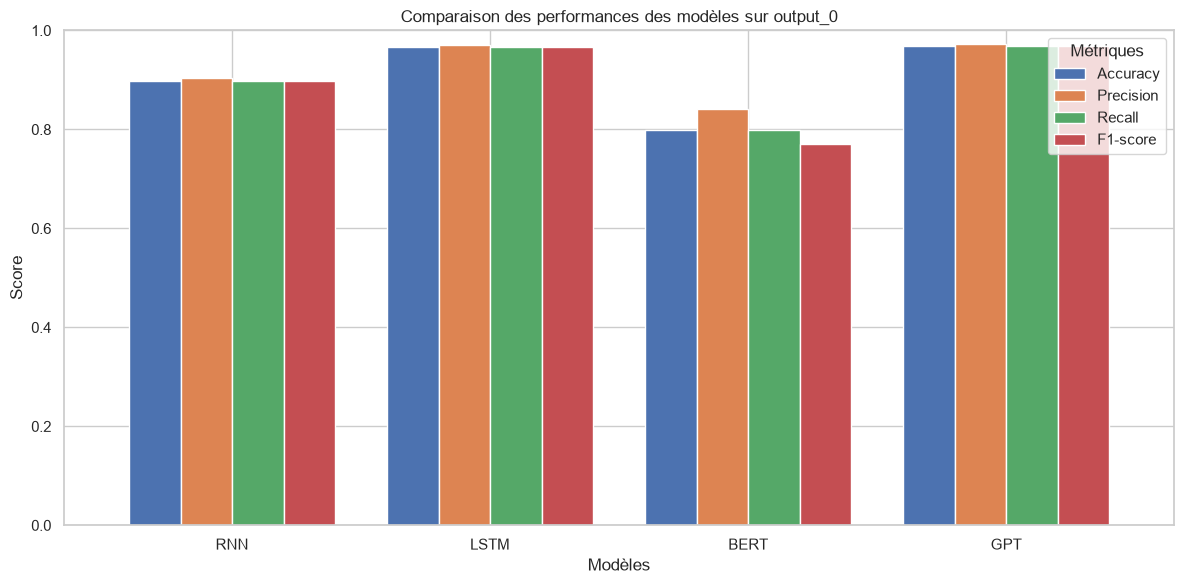

In [6]:
metriques = ["Accuracy", "Precision", "Recall", "F1-score"]

comparaison.plot(
    x="Modèle",
    y=metriques,
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Comparaison des performances des modèles sur output_0")
plt.ylabel("Score")
plt.xlabel("Modèles")
plt.xticks(rotation=0)
plt.legend(title="Métriques")
plt.tight_layout()
plt.show()

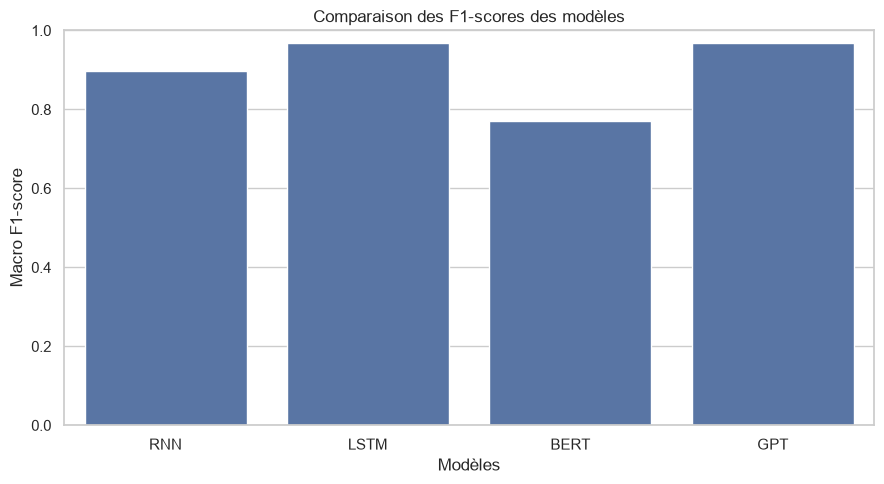

In [7]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparaison,
    x="Modèle",
    y="F1-score"
)

plt.title("Comparaison des F1-scores des modèles")
plt.ylabel("Macro F1-score")
plt.xlabel("Modèles")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [8]:
meilleur = comparaison.loc[comparaison["F1-score"].idxmax()]

print("Meilleur modèle :", meilleur["Modèle"])
print("Accuracy :", meilleur["Accuracy"])
print("Precision :", meilleur["Precision"])
print("Recall :", meilleur["Recall"])
print("F1-score :", meilleur["F1-score"])

Meilleur modèle : GPT
Accuracy : 0.9685714285714285
Precision : 0.971902406845412
Recall : 0.9685714285714285
F1-score : 0.9683349956225005


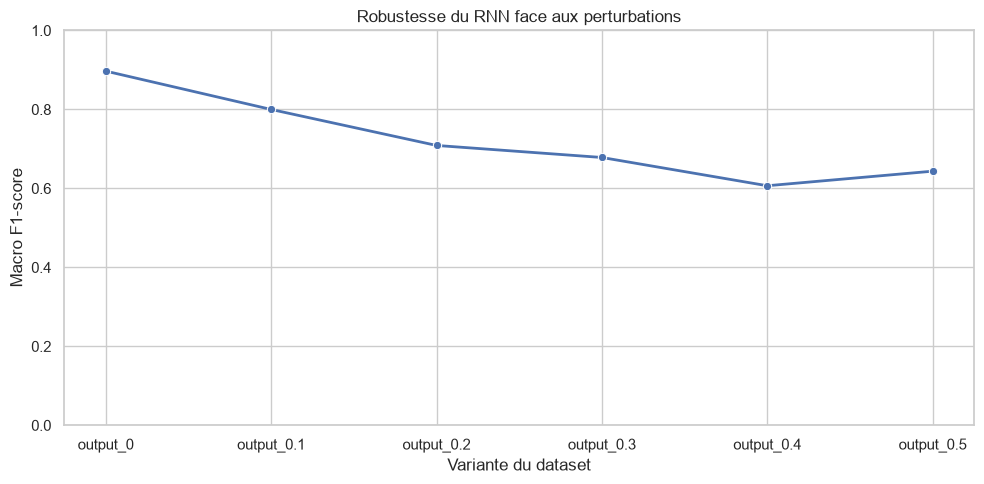

In [10]:
rnn = pd.read_csv("resultats_rnn/comparaison_rnn.csv")

rnn.columns = rnn.columns.str.strip().str.lower()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=rnn,
    x="variante",
    y="f1_macro",
    marker="o",
    linewidth=2
)

plt.title("Robustesse du RNN face aux perturbations")
plt.xlabel("Variante du dataset")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()